In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC, LinearSVC

RANDOM_STATE = 42

## Data Ingestion and Cleaning

In [11]:
df = pd.read_csv('sarcasm_cleanedV3.csv')

df.head()

,is_sarcastic,headline,article_link,word_count,cleaned_headline
0,1,thirtysomething scientists unveil doomsday clo...,https://www.theonion.com/thirtysomething-scien...,8,thirtysomething scientists unveil doomsday clo...
1,0,dem rep. totally nails why congress is falling...,https://www.huffingtonpost.com/entry/donna-edw...,13,dem rep totally nails why congress is falling ...
2,0,eat your veggies: 9 deliciously different recipes,https://www.huffingtonpost.com/entry/eat-your-...,7,eat your veggies 9 deliciously different recipes
3,1,inclement weather prevents liar from getting t...,https://local.theonion.com/inclement-weather-p...,8,inclement weather prevents liar from getting t...
4,1,mother comes pretty close to using word 'strea...,https://www.theonion.com/mother-comes-pretty-c...,9,mother comes pretty close to using word stream...


In [12]:
print("Shape of the dataset:", df.shape)

Shape of the dataset: (28503, 5)


In [13]:
print("Number of missing values in each column:")
print(df.isnull().sum())

Number of missing values in each column:
is_sarcastic        0
headline            0
article_link        0
word_count          0
cleaned_headline    0
dtype: int64


In [14]:
# Dropping the only missing row
df = df.dropna()

print("Number of missing values after handling nulls:")
print(df.isnull().sum())

Number of missing values after handling nulls:
is_sarcastic        0
headline            0
article_link        0
word_count          0
cleaned_headline    0
dtype: int64


In [15]:
print("Number of duplicate rows in the dataset:", df.duplicated().sum())

Number of duplicate rows in the dataset: 0


## Straified splitting 70/15/15 

In [16]:
X = df['cleaned_headline']
y = df['is_sarcastic']

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=RANDOM_STATE)

print("Training set size:", X_train.shape[0])
print("Validation set size:", X_val.shape[0])
print("Test set size:", X_test.shape[0])
print("â€”" * 50)
print(f"Training set class distribution: {y_train.value_counts(normalize=True).map('{:.3f}'.format)}")
print(f"\nValidation set class distribution: {y_val.value_counts(normalize=True).map('{:.3f}'.format)}")
print(f"\nTest set class distribution: {y_test.value_counts(normalize=True).map('{:.3f}'.format)}")

Training set size: 19952
Validation set size: 4275
Test set size: 4276
â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”â€”
Training set class distribution: is_sarcastic
0    0.525
1    0.475
Name: proportion, dtype: object

Validation set class distribution: is_sarcastic
0    0.524
1    0.476
Name: proportion, dtype: object

Test set class distribution: is_sarcastic
0    0.525
1    0.475
Name: proportion, dtype: object


## TF-IDF Vectorization

In [17]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

In [18]:
#max_features_list = [10000, 20000, 50000, 100000, 200000, 300000]
#C_list = [0.1, 1, 10, 100]
#results = []
#
#for max_features in max_features_list:
#    vectorizer = TfidfVectorizer(max_features=max_features, ngram_range=(2, 5), analyzer='char', min_df=2, sublinear_tf=True)
#    X_train_tfidf = vectorizer.fit_transform(X_train)
#    X_val_tfidf = vectorizer.transform(X_val)
#
#    for c in C_list:
#        model = LogisticRegression(C=c, random_state=RANDOM_STATE, max_iter=10000)
#        model.fit(X_train_tfidf, y_train)
#
#        results.append({
#            "max_features": max_features,
#            "C": c,
#            "train_f1": f1_score(y_train, model.predict(X_train_tfidf)),
#            "val_f1": f1_score(y_val, model.predict(X_val_tfidf)),
#        })
#
#results_df = pd.DataFrame(results)
#results_df["gap"] = results_df["train_f1"] - results_df["val_f1"]
#results_df = results_df.round(4)
#results_df.sort_values(by=["val_f1", "train_f1"], ascending=False, inplace=True)
#results_df

In [19]:
# Final TF-IDF vectorizer (max_features=150000, ngram_range=(1, 2))
vectorizer = TfidfVectorizer(max_features=150000, ngram_range=(1, 2), sublinear_tf=True)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_val_tfidf = vectorizer.transform(X_val)
X_test_tfidf = vectorizer.transform(X_test)

In [20]:
print(f"Vocabulary size: {len(vectorizer.get_feature_names_out())}")
print("Max features: 150000")
print("ngram_range: (1, 2)\n")
print(f"Shape of the TF-IDF matrix for training set: {X_train_tfidf.shape}")
print(f"Shape of the TF-IDF matrix for validation set: {X_val_tfidf.shape}")
print(f"Shape of the TF-IDF matrix for test set: {X_test_tfidf.shape}") 

Vocabulary size: 147269
Max features: 150000
ngram_range: (1, 2)

Shape of the TF-IDF matrix for training set: (19952, 147269)
Shape of the TF-IDF matrix for validation set: (4275, 147269)
Shape of the TF-IDF matrix for test set: (4276, 147269)


## Logistic Regression Model

C=1: Train F1 Score=0.9436, Validation F1 Score=0.8445
C=2: Train F1 Score=0.9700, Validation F1 Score=0.8534
C=3: Train F1 Score=0.9849, Validation F1 Score=0.8546
C=5: Train F1 Score=0.9948, Validation F1 Score=0.8581
C=10: Train F1 Score=0.9993, Validation F1 Score=0.8609
C=100: Train F1 Score=1.0000, Validation F1 Score=0.8585
C=200: Train F1 Score=1.0000, Validation F1 Score=0.8574
C=300: Train F1 Score=1.0000, Validation F1 Score=0.8590
Max validation F1 Score: 0.8609 at C=10


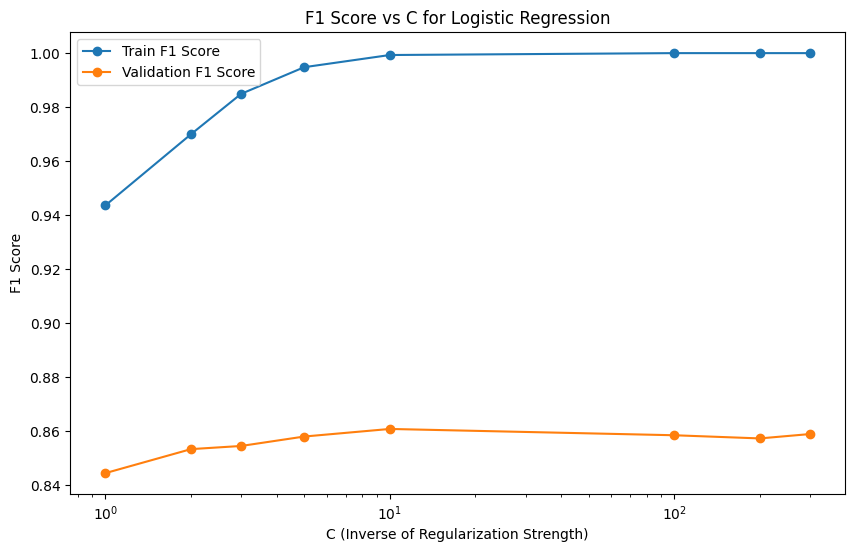

In [21]:
C_values = [1, 2, 3, 5, 10, 100, 200, 300]
train_f1_scores = []
val_f1_scores = []
for C in C_values:
    model = LogisticRegression(C=C, random_state=RANDOM_STATE, max_iter=10000)
    model.fit(X_train_tfidf, y_train)
    train_f1= f1_score(y_train, model.predict(X_train_tfidf), average='weighted')
    val_f1 = f1_score(y_val, model.predict(X_val_tfidf), average='weighted')
    print(f"C={C}: Train F1 Score={train_f1:.4f}, Validation F1 Score={val_f1:.4f}")
    train_f1_scores.append(train_f1)
    val_f1_scores.append(val_f1)
print(f"Max validation F1 Score: {max(val_f1_scores):.4f} at C={C_values[val_f1_scores.index(max(val_f1_scores))]}")

plt.subplots(figsize=(10, 6))
plt.plot(C_values, train_f1_scores, marker='o', label='Train F1 Score')
plt.plot(C_values, val_f1_scores, marker='o', label='Validation F1 Score')
plt.xscale('log')
plt.xlabel('C (Inverse of Regularization Strength)')
plt.ylabel('F1 Score')
plt.title('F1 Score vs C for Logistic Regression')
plt.legend()
plt.show()

### Insight
- Training F1 rises steadily as `C` increases peaking at **0.9999**. Validation F1 peaks around `C=10` **(0.8609)** and then declines, falling to about **0.8581** at `C=100`. This decline in validation is a clear sign of overfitting at large C.
 
- We choose `C=10` because it gives the **highest validation F1 score** and is the peak before the decline and overfitting starts to occur.


In [22]:
# Best settings, C=10
lr_model = LogisticRegression(C=10, random_state=RANDOM_STATE, max_iter=10000)
lr_model.fit(X_train_tfidf, y_train)

LogisticRegression(C=10, max_iter=10000, random_state=42)

## Linear SVM 

C=0.01: Train F1 Score=0.8643, Validation F1 Score=0.8016
C=0.05: Train F1 Score=0.9130, Validation F1 Score=0.8296
C=0.1: Train F1 Score=0.9448, Validation F1 Score=0.8459
C=1: Train F1 Score=0.9998, Validation F1 Score=0.8620
C=2: Train F1 Score=1.0000, Validation F1 Score=0.8620
C=5: Train F1 Score=1.0000, Validation F1 Score=0.8632
C=10: Train F1 Score=1.0000, Validation F1 Score=0.8627
Max validation F1 Score: 0.8632 at C=5


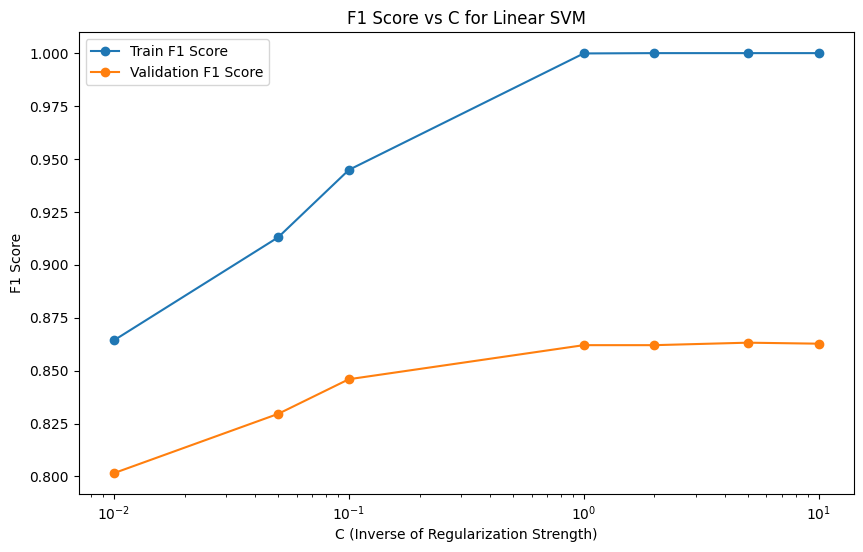

In [23]:
C_values = [0.01, 0.05, 0.1, 1, 2, 5, 10]
train_f1_scores = []
val_f1_scores = []
for c in C_values:
    model = LinearSVC(C=c, random_state=RANDOM_STATE, max_iter=10000)
    model.fit(X_train_tfidf, y_train)
    train_f1 = f1_score(y_train, model.predict(X_train_tfidf), average='weighted')
    val_f1 = f1_score(y_val, model.predict(X_val_tfidf), average='weighted')
    print(f"C={c}: Train F1 Score={train_f1:.4f}, Validation F1 Score={val_f1:.4f}")
    train_f1_scores.append(train_f1)
    val_f1_scores.append(val_f1)
print(f"Max validation F1 Score: {max(val_f1_scores):.4f} at C={C_values[val_f1_scores.index(max(val_f1_scores))]}")

plt.subplots(figsize=(10, 6))
plt.plot(C_values, train_f1_scores, marker='o', label='Train F1 Score')
plt.plot(C_values, val_f1_scores, marker='o', label='Validation F1 Score')
plt.xscale('log')
plt.xlabel('C (Inverse of Regularization Strength)')
plt.ylabel('F1 Score')
plt.title('F1 Score vs C for Linear SVM')
plt.legend()
plt.show()

### Insight
- Validation F1 rises from `C=0.1` to a peak at `C=5` (0.8632), while training F1 keeps rising, so we stop at the validation peak to avoid overfitting.

- We choose `C=5` for the highest validation F1.

In [24]:
# Best settings, C=5
svm_model = LinearSVC(C=5, random_state=RANDOM_STATE, max_iter=10000)
svm_model.fit(X_train_tfidf, y_train)

LinearSVC(C=5, max_iter=10000, random_state=42)

## Ensemble of LR and SVM (Bonus)

In [25]:
from sklearn.ensemble import StackingClassifier

estimators = [
    ('lr', lr_model),
    ('svm', svm_model)
]

meta_model = LogisticRegression(random_state=RANDOM_STATE)

stacking_model = StackingClassifier(estimators=estimators, final_estimator=meta_model, cv=5)

stacking_model.fit(X_train_tfidf, y_train)
y_pred = stacking_model.predict(X_val_tfidf)

print("Training F1 Score:", f1_score(y_train, stacking_model.predict(X_train_tfidf)))
print("Validation F1 Score:", f1_score(y_val, y_pred))

Training F1 Score: 1.0
Validation F1 Score: 0.8562362704417866


## Test Evaluation of 3 models

In [26]:
models = {
    "Logistic Regression": lr_model,
    "Linear SVM": svm_model,
    "Stacking (LR + SVM)": stacking_model,
}

class_names = ["Not Sarcastic", "Sarcastic"]
summary = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test_tfidf)
    predictions[name] = y_pred
    summary.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (sarcastic)": precision_score(y_test, y_pred),
        "Recall (sarcastic)": recall_score(y_test, y_pred),
        "F1 (sarcastic)": f1_score(y_test, y_pred),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro"),
    })

summary_df = pd.DataFrame(summary).set_index("Model").round(4)
summary_df



,Accuracy,Precision (sarcastic),Recall (sarcastic),F1 (sarcastic),F1 (macro)
Model,,,,,
Logistic Regression,0.8508,0.8424,0.8441,0.8432,0.8504
Linear SVM,0.8510,0.8425,0.8446,0.8435,0.8507
Stacking (LR + SVM),0.8517,0.8454,0.8421,0.8438,0.8513


In [27]:
for name, y_pred in predictions.items():
    print(f"\t\t{name}\n")
    print(classification_report(y_test, y_pred, target_names=class_names, digits=4))
    print("—"*55)

		Logistic Regression

               precision    recall  f1-score   support

Not Sarcastic     0.8584    0.8569    0.8577      2243
    Sarcastic     0.8424    0.8441    0.8432      2033

     accuracy                         0.8508      4276
    macro avg     0.8504    0.8505    0.8504      4276
 weighted avg     0.8508    0.8508    0.8508      4276

———————————————————————————————————————————————————————
		Linear SVM

               precision    recall  f1-score   support

Not Sarcastic     0.8588    0.8569    0.8578      2243
    Sarcastic     0.8425    0.8446    0.8435      2033

     accuracy                         0.8510      4276
    macro avg     0.8506    0.8507    0.8507      4276
 weighted avg     0.8510    0.8510    0.8510      4276

———————————————————————————————————————————————————————
		Stacking (LR + SVM)

               precision    recall  f1-score   support

Not Sarcastic     0.8574    0.8605    0.8589      2243
    Sarcastic     0.8454    0.8421    0.8438      2

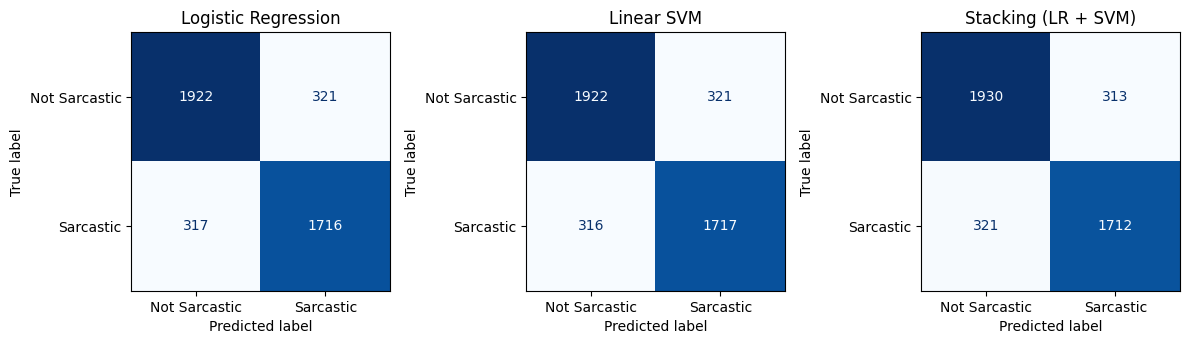

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## Models Misclassification Analysis
- **Logistic Regression** and **Linear SVM** are pratically the same in numbers of correctly classified and missclassifed samples. The ensemble model is slightl better at **correctly classifying samples** (higher True Positives) and **lowering mistaking correct samples for incorrect ones** (lower False Positives) but it does worse at **correctly classifying incorrect samples** (lower True Negatives) and **mistaking incorrect samples for correct ones** (higher False Negatives).

In [29]:
# Top words affected that affect LR predictions
words = vectorizer.get_feature_names_out()
lr_coefs = lr_model.coef_[0]

coef_df = pd.DataFrame({
    "Word": words,
    "Coefficient": lr_coefs
})
# Words that strongly indicate Class 1 (Sarcastic)
print("Top 10 positive coefficients (Sarcastic):")
display(coef_df.sort_values(by="Coefficient", ascending=False).head(10))

# Words that strongly indicate Class 0 (Not Sarcastic)
print("\nTop 10 negative coefficients (Not Sarcastic):")
display(coef_df.sort_values(by="Coefficient", ascending=True).head(10))

Top 10 positive coefficients (Sarcastic):


,Word,Coefficient
83555,nation,14.088614
9550,area,12.486819
76557,man,11.907929
106247,report,9.969169
87962,of,8.324259
8152,announces,7.873768
74439,local,7.851846
56945,he,7.480157
92529,only,7.340196
50396,fucking,7.161589



Top 10 negative coefficients (Not Sarcastic):


,Word,Coefficient
125429,the,-22.559578
66221,is,-17.110416
6931,and,-14.989773
133622,trump,-11.780288
142103,why,-10.082177
146688,your,-9.608001
9226,are,-9.385706
6637,an,-8.112540
82994,my,-7.411415
60581,how,-7.286178


## Saving Vectorizer and Models

In [30]:
import joblib

joblib.dump(vectorizer, "../models/text/tfidf_vectorizer.pkl")
joblib.dump(lr_model, "../models/text/logistic_regression_model.pkl")
joblib.dump(svm_model, "../models/text/linear_svm_model.pkl")
joblib.dump(stacking_model, "../models/text/stacking_model.pkl")

['../models/text/stacking_model.pkl']